<a href="https://colab.research.google.com/github/puvvalakrishna96-stack/concrete_strength_predictor/blob/devop/concrete_strength_prdector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install xlrd -q

import pandas as pd

df = pd.read_excel("Concrete_Data.xls")

print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.isnull().sum())

(1030, 9)
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']
   Cement (component 1)(kg in a m^3 mixture)  \
0                                      540.0   
1                                      540.0   
2                                      332.5   
3                                      332.5   
4                                      198.6   

   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  \
0                                                0.0       
1                                                0.0       
2                                              142.5       
3                                     

            cement         slag      fly_ash        water  superplasticizer  \
count  1030.000000  1030.000000  1030.000000  1030.000000       1030.000000   
mean    281.165631    73.895485    54.187136   181.566359          6.203112   
std     104.507142    86.279104    63.996469    21.355567          5.973492   
min     102.000000     0.000000     0.000000   121.750000          0.000000   
25%     192.375000     0.000000     0.000000   164.900000          0.000000   
50%     272.900000    22.000000     0.000000   185.000000          6.350000   
75%     350.000000   142.950000   118.270000   192.000000         10.160000   
max     540.000000   359.400000   200.100000   247.000000         32.200000   

        coarse_agg     fine_agg          age     strength  
count  1030.000000  1030.000000  1030.000000  1030.000000  
mean    972.918592   773.578883    45.662136    35.817836  
std      77.753818    80.175427    63.169912    16.705679  
min     801.000000   594.000000     1.000000    

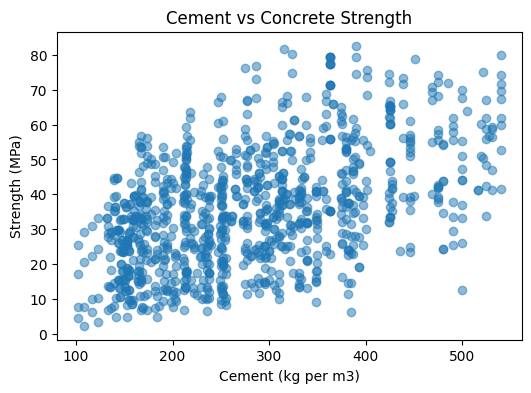

In [3]:
import matplotlib.pyplot as plt

df.columns = ["cement", "slag", "fly_ash", "water",
              "superplasticizer", "coarse_agg", "fine_agg",
              "age", "strength"]

print(df.describe())

print("\nCorrelation of each column with strength:")
print(df.corr()["strength"].sort_values(ascending=False))

plt.figure(figsize=(6, 4))
plt.scatter(df["cement"], df["strength"], alpha=0.5)
plt.xlabel("Cement (kg per m3)")
plt.ylabel("Strength (MPa)")
plt.title("Cement vs Concrete Strength")
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

X = df.drop("strength", axis=1)
y = df["strength"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name)
    print("  R2 score:", round(r2_score(y_test, pred), 3))
    print("  Mean error (MPa):", round(mean_absolute_error(y_test, pred), 2))

# Which ingredients matter most to the Random Forest?
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns)
print("\nFeature importance:")
print(importance.sort_values(ascending=False).round(3))

Linear Regression
  R2 score: 0.628
  Mean error (MPa): 7.75
Random Forest
  R2 score: 0.88
  Mean error (MPa): 3.78

Feature importance:
age                 0.333
cement              0.324
water               0.124
slag                0.076
superplasticizer    0.059
fine_agg            0.036
coarse_agg          0.028
fly_ash             0.020
dtype: float64


In [5]:
sample = pd.DataFrame([{
    "cement": 350, "slag": 100, "fly_ash": 0, "water": 160,
    "superplasticizer": 8, "coarse_agg": 1000, "fine_agg": 800, "age": 28
}])

print("Predicted strength:", round(rf.predict(sample)[0], 1), "MPa")

Predicted strength: 59.5 MPa
